# Generalized Random Network Test

This notebook performs a complete workflow for testing random percolation networks:

1. **Generate random paths** (following PiaNo.ipynb approach)
2. **Check for dead-ends** in the percolation path
3. **Apply pruning** if there are dangling bonds
4. **Visualize** the network before and after pruning
5. **Calculate impedance** using the incidence matrix method

---
## 1. Setup and Imports

In [ ]:
# Environment and path setup is handled in the next cell.


In [ ]:
import math
import sys
import os
import numpy as np
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    utils_path = "/content/drive/MyDrive/ColabProject/utils"
    print("Environment: Google Colab")
except ImportError:
    utils_path = os.path.abspath(os.path.join(os.getcwd(), "..", "utils"))
    print("Environment: Local")

if utils_path not in sys.path:
    sys.path.append(utils_path)

print(f"Utils path: {utils_path}")
print(f"Files available: {os.listdir(utils_path)}")

Utils path: <project_root>/utils
Files available: ['filtered_paths.py', 'network_merge_explained.png', 'utility_reset.py', 'PiaNo.ipynb', 'plotting_old.py', '.DS_Store', 'rebuild_log.txt', 'result_exporter.py', 'path_analysis.py', 'testing_paths.ipynb', 'test_paths_in_subregions.ipynb', 'pdf_generator.py', 'node_edge_mapping_analysis.ipynb', 'plotting.py', 'path_pairs_of_lines vs  path_pairs_of_edges.txt', 'test_random_network_impedance.ipynb', 'pruning.py', 'point_generator.py', '__pycache__', 'rebuild_experiments.py', 'edge_discovery.py', 'nextSteps.txt', 'region_checks.py', 'calculating_the_impedance_of_a_graph.ipynb', 'network_visualization.py', 'test_simple_percolation.ipynb', 'test_merge.py', 'testing_points_in_subregions.ipynb', 'intersection_utils.py', 'impedance_calculator.py', 'testing_data_structures.ipynb', 'exemplo_impedance.ipynb', 'node_edge_visualization_with_ids.ipynb', 'experiment_manager.py', 'boundary_utils.py', 'test_pruning_with_dangling_bonds.ipynb']


In [ ]:
import importlib
import point_generator as point_generator_module
import result_exporter as result_exporter_module

importlib.reload(point_generator_module)
importlib.reload(result_exporter_module)

from point_generator import *
from region_checks import *
from intersection_utils import *
from path_analysis import *
from plotting import *
from pruning import *
from filtered_paths import *
from utility_reset import *
from impedance_calculator import *
from experiment_manager import ExperimentManager, setup_experiment, load_network
from edge_discovery import discover_consecutive_edges, check_dead_ends
from network_visualization import (
    plot_random_lines, plot_intersections,
    plot_percolating_paths_before_pruning, plot_before_after_pruning,
    plot_network_with_impedance, plot_before_after_merge
)
from result_exporter import (
    build_nodes_detailed, build_edges_detailed,
    build_percolating_paths_detailed, build_lines_info,
    calculate_impedance_vs_k, build_experiment_summary,
    print_impedance_summary, print_export_summary
)

print("All modules imported successfully!")

All modules imported successfully!


In [ ]:
# ============================================================================
# EXPERIMENT CONFIGURATION - Using ExperimentManager module
# ============================================================================
# This cell configures automatic saving of all experiment results.
# Works seamlessly on both local environment and Google Colab.

import json
from datetime import datetime

# Initialize experiment manager
exp_manager = setup_experiment()

# Create convenient aliases for compatibility
IN_COLAB = exp_manager.in_colab
EXPERIMENT_NUMBER = exp_manager.experiment_number
EXPERIMENT_TIMESTAMP = exp_manager.timestamp
EXPERIMENT_DIR = exp_manager.experiment_dir
RESULTS_BASE_DIR = exp_manager.base_dir

# Wrapper functions for backward compatibility
def save_figure(fig, filename, dpi=150):
    return exp_manager.save_figure(fig, filename, dpi)

def save_json(data, filename):
    return exp_manager.save_json(data, filename)

# Print configuration
exp_manager.print_config()

EXPERIMENT CONFIGURATION
  Environment: Local
  Experiment #: 72
  Timestamp: 20260331_095049
  Results directory: <project_root>/utils/../experiments/exp_72

EXPERIMENT CONFIGURATION
  Environment: Local
  Experiment #: 72
  Timestamp: 20260331_095049
  Results directory: <project_root>/utils/../experiments/exp_72



---
## 2. Generate Random Network

Parameters:
- `a`: aspect ratio (length of sticks)
- `N`: number of sticks/segments

In [ ]:
# ═══════════════════════════════════════════════════════════════════════
# NETWORK PARAMETERS
# ═══════════════════════════════════════════════════════════════════════
a = 0.60  # Aspect ratio (length of sticks)
N = 30    # Number of sticks

print(f"Generating random network with:")
print(f"  - Aspect ratio (a): {a}")
print(f"  - Number of sticks (N): {N}")

Generating random network with:
  - Aspect ratio (a): 0.6
  - Number of sticks (N): 30


### (Optional) Load a Previously Saved Network

To **reload** a network from a previous experiment instead of generating a new one,
set `LOAD_EXPERIMENT` to the experiment number below and run this cell.
The loaded data will override `a`, `N`, `points_1`, `points_2`, and `angles`,
so you can skip the "Generate Random Points" cell and go straight to intersections.

Set `LOAD_EXPERIMENT = None` (default) to generate a fresh random network as usual.

In [ ]:
# ═══════════════════════════════════════════════════════════════════════
# LOAD A PREVIOUS NETWORK (set to an experiment number, or None to skip)
# ═══════════════════════════════════════════════════════════════════════
LOAD_EXPERIMENT =   # e.g. 5 to reload exp_5

if LOAD_EXPERIMENT is not None:
    loaded = load_network(LOAD_EXPERIMENT)
    a = loaded["a"]
    N = loaded["N"]
    points_1 = loaded["points_1"]
    points_2 = loaded["points_2"]
    angles = loaded["angles"]
    print(f"Network loaded from experiment {LOAD_EXPERIMENT}. "
          f"Skip the 'Generate Random Points' cell and proceed to intersections.")
else:
    print("No experiment to load. A fresh network will be generated below.")

In [ ]:
# ═══════════════════════════════════════════════════════════════════════
# INITIALIZE DATA STRUCTURES
# ═══════════════════════════════════════════════════════════════════════
points_1 = []
points_2 = []
angles = []
graph = []  # edges
nodes = []
intersected_line_1 = []
intersected_line_2 = []
intersections_points = []
all_connected_nodes = []
solutions = []
A = []
L = []
paths = []

print("Data structures initialized")

Data structures initialized


In [ ]:
# ═══════════════════════════════════════════════════════════════════════
# GENERATE RANDOM POINTS
# ═══════════════════════════════════════════════════════════════════════
generate_points(N, points_1, points_2, angles, a, enforce_bounds=True)

print(f"Generated {N} random segments")
print(f"  points_1: {len(points_1)} points")
print(f"  points_2: {len(points_2)} points")
print(f"  angles: {len(angles)} angles")

# Bound-check diagnostics for generated sticks
all_x = [p[0] for p in points_1] + [p[0] for p in points_2]
all_y = [p[1] for p in points_1] + [p[1] for p in points_2]

print(f"  x-range: [{min(all_x):.6f}, {max(all_x):.6f}]")
print(f"  y-range: [{min(all_y):.6f}, {max(all_y):.6f}]")

violations = validate_segments_bounds(points_1, points_2)
if violations:
    print(f"  WARNING: {len(violations)} out-of-bounds segments found")
    print(f"  First violation: {violations[0]}")
    raise ValueError("Out-of-bounds sticks detected.")
else:
    print("  All sticks are inside [0, 1] x [0, 1]")

Generated 30 random segments
  points_1: 30 points
  points_2: 30 points
  angles: 30 angles
  x-range: [0.009782, 0.956108]
  y-range: [0.010809, 0.997734]
  All sticks are inside [0, 1] x [0, 1]


In [ ]:
# ═══════════════════════════════════════════════════════════════════════
# IDENTIFY INTERSECTIONS
# ═══════════════════════════════════════════════════════════════════════
intersections_points, intersected_line_1, intersected_line_2, graph = identify_intersections(
    points_1, points_2, intersections_points, intersected_line_1,
    intersected_line_2, graph, angles, a, N
)

print(f"\nIntersection analysis:")
print(f"  Total intersections found: {len(intersections_points)}")
print(f"  Intersected lines: {len(intersected_line_1)}")


Intersection analysis:
  Total intersections found: 118
  Intersected lines: 236


---
## 3. Find Boundary Conditions (Source and Drain)

In [ ]:
# ═══════════════════════════════════════════════════════════════════════
# IDENTIFY BOUNDARY NODES (STRICT - NO FALLBACK)
# ═══════════════════════════════════════════════════════════════════════
boundary_condition_source = []
boundary_condition_drain = []

for i, (x, y) in enumerate(intersections_points):
    if x < 0.1:
        boundary_condition_source.append(i)
    elif x > 0.9:
        boundary_condition_drain.append(i)

print("Boundary conditions:")
print(f"  Source (x < 0.1): {len(boundary_condition_source)} nodes -> {boundary_condition_source}")
print(f"  Drain (x > 0.9): {len(boundary_condition_drain)} nodes -> {boundary_condition_drain}")

if not boundary_condition_source or not boundary_condition_drain:
    raise ValueError(
        "Boundary conditions not satisfied strictly: "
        f"source_nodes={len(boundary_condition_source)}, "
        f"drain_nodes={len(boundary_condition_drain)}. "
        "No fallback is allowed. Regenerate network (or adjust N/a)."
    )

print("  Strict boundary conditions satisfied (no fallback used)")

Boundary conditions:
  Source (x < 0.1): 1 nodes -> [89]
  Drain (x > 0.9): 1 nodes -> [71]
  Strict boundary conditions satisfied (no fallback used)


In [ ]:
# ═══════════════════════════════════════════════════════════════════════
# IDENTIFY SOURCE AND DRAIN SEGMENTS (STRICT BOUNDARY NODES)
# ═══════════════════════════════════════════════════════════════════════
source_segments = set()
drain_segments = set()

for node_idx in boundary_condition_source:
    if node_idx >= len(graph):
        raise IndexError(f"Source boundary node {node_idx} is out of graph range {len(graph)}")
    source_segments.update(graph[node_idx])

for node_idx in boundary_condition_drain:
    if node_idx >= len(graph):
        raise IndexError(f"Drain boundary node {node_idx} is out of graph range {len(graph)}")
    drain_segments.update(graph[node_idx])

print(f"\nBoundary segments:")
print(f"  Source segments: {source_segments}")
print(f"  Drain segments: {drain_segments}")


Boundary segments:
  Source segments: {17, 13}
  Drain segments: {16, 9}


---
## 4. Find Percolation Paths

In [ ]:
# ═══════════════════════════════════════════════════════════════════════
# FIND ALL PERCOLATION PATHS
# ═══════════════════════════════════════════════════════════════════════
path_nodes = []
path_pairs_of_lines = []
path_pairs_of_edges = []
all_path_perc = []

for i in boundary_condition_source:
    do_not_check = 0
    number_path = len(path_nodes)
    for k in range(0, number_path):
        if i in path_nodes[k]:
            do_not_check = 1
    if do_not_check == 0:
        print(f"Finding path from node {i}...")
        start_node = i
        nodes, pair_of_lines, pair_of_edges, path_perc = find_path(
            intersections_points, graph, start_node
        )
        path_nodes.append(nodes)
        path_pairs_of_lines.append(pair_of_lines)
        path_pairs_of_edges.append(pair_of_edges)
        all_path_perc.append(path_perc)
        print(f"  Path found: {len(nodes)} nodes, percolating: {path_perc == 1}")

Finding path from node 89...
valor de queue antes = deque([89])
valor de queue depois = deque([])
nós visitados {89}
valor de target edge = (13, 17)
valor de path_pairs_of_lines = [(13, 17)]
valor do i = 27
valor do current node = 89
valor da queue após append = deque([27])
valor do path_pairs_of_nodes[89, 27]
valor do path_pairs_of_lines = [(13, 17), (3, 13)]
valor do path_pairs_of_edges = [(89, 27)]
valor do i = 54
valor do current node = 89
valor da queue após append = deque([27, 54])
valor do path_pairs_of_nodes[89, 27, 54]
valor do path_pairs_of_lines = [(13, 17), (3, 13), (6, 13)]
valor do path_pairs_of_edges = [(89, 27), (89, 54)]
valor do i = 60
valor do current node = 89
valor da queue após append = deque([27, 54, 60])
valor do path_pairs_of_nodes[89, 27, 54, 60]
valor do path_pairs_of_lines = [(13, 17), (3, 13), (6, 13), (7, 13)]
valor do path_pairs_of_edges = [(89, 27), (89, 54), (89, 60)]
valor do i = 64
valor do current node = 89
valor da queue após append = deque([27, 54,

In [ ]:
# ═══════════════════════════════════════════════════════════════════════
# PATH SUMMARY
# ═══════════════════════════════════════════════════════════════════════
print("="*70)
print("PATH SUMMARY (BEFORE PRUNING)")
print("="*70)

print(f"\nTotal paths found: {len(path_nodes)}")
print(f"Percolating paths: {sum(1 for p in all_path_perc if p == 1)}")

for i, (nodes, lines, edges, perc) in enumerate(zip(path_nodes, path_pairs_of_lines, path_pairs_of_edges, all_path_perc)):
    perc_status = "PERCOLATING" if perc == 1 else "NOT percolating"
    print(f"\nPath {i}: {perc_status}")
    print(f"  Nodes: {nodes}")
    print(f"  Line pairs: {lines}")
    print(f"  Edge pairs: {edges}")

PATH SUMMARY (BEFORE PRUNING)

Total paths found: 1
Percolating paths: 1

Path 0: PERCOLATING
  Nodes: [89, 27, 54, 60, 64, 90, 91, 92, 93, 26, 28, 29, 30, 18, 32, 45, 53, 55, 56, 57, 58, 19, 33, 46, 59, 61, 62, 63, 65, 66, 67, 39, 50, 78, 96, 102, 107, 22, 42, 51, 74, 84, 97, 104, 111, 112, 79, 98, 105, 114, 100, 106, 115, 13, 103, 14, 110, 10, 15, 23, 75, 113, 0, 16, 17, 20, 21, 24, 25, 1, 31, 34, 35, 36, 37, 38, 40, 41, 43, 44, 2, 47, 48, 49, 52, 4, 68, 80, 81, 82, 83, 85, 86, 7, 70, 99, 87, 116, 77, 3, 69, 71, 72, 73, 76, 11, 88, 117, 5, 6, 8, 9, 12, 94, 95, 101, 108, 109]
  Line pairs: [(13, 17), (3, 13), (6, 13), (7, 13), (8, 13), (13, 19), (13, 23), (13, 27), (13, 29), (3, 8), (3, 18), (3, 22), (3, 24), (2, 6), (4, 6), (5, 6), (6, 11), (6, 15), (6, 18), (6, 24), (6, 25), (2, 7), (4, 7), (5, 7), (7, 10), (7, 15), (7, 18), (7, 25), (8, 18), (8, 24), (8, 27), (4, 19), (5, 19), (10, 19), (15, 19), (18, 19), (19, 25), (2, 23), (4, 23), (5, 23), (9, 23), (11, 23), (15, 23), (18, 23), 

---
## 5. Visualize Network BEFORE Pruning

Visualization: All randomly generated lines
  [OK] Figure saved: 01_random_lines_N30.png


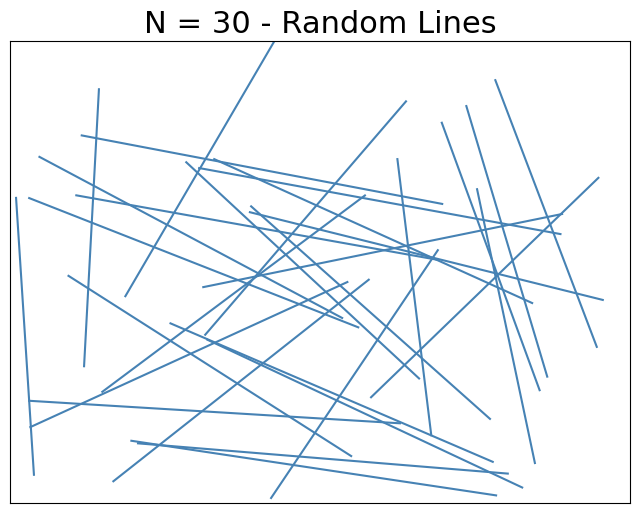

In [ ]:
# ═══════════════════════════════════════════════════════════════════════
# PLOT ALL RANDOM LINES
# ═══════════════════════════════════════════════════════════════════════
print("Visualization: All randomly generated lines")

# Create figure for saving
fig_lines = plt.figure(figsize=(8, 6))
for i in range(N):
    plt.plot([points_1[i][0], points_2[i][0]], [points_1[i][1], points_2[i][1]],
             linestyle='-', color='steelblue')
plt.title(f'N = {N} - Random Lines', fontsize=22)
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.xticks([])
plt.yticks([])
plt.grid(True, linestyle='dotted', linewidth=0.5, color='gray')
save_figure(fig_lines, f'01_random_lines_N{N}.png')
plt.show()

Visualization: Lines with intersection points
  [OK] Figure saved: 02_intersections_N30.png


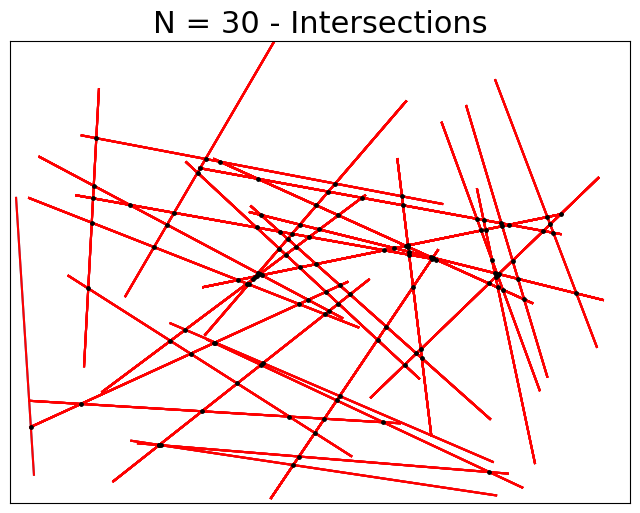

In [ ]:
# ═══════════════════════════════════════════════════════════════════════
# PLOT LINES WITH INTERSECTIONS
# ═══════════════════════════════════════════════════════════════════════
print("Visualization: Lines with intersection points")

if intersections_points:
    fig_intersections = plt.figure(figsize=(8, 6))

    # Plot all lines
    for i in range(N):
        plt.plot([points_1[i][0], points_2[i][0]], [points_1[i][1], points_2[i][1]],
                 linestyle='-', color='steelblue', zorder=0)

    # Plot intersected lines in red
    for i in range(len(intersected_line_1)):
        plt.plot([intersected_line_1[i][0], intersected_line_2[i][0]],
                 [intersected_line_1[i][1], intersected_line_2[i][1]],
                 linestyle='-', color='red', zorder=1)

    # Plot intersection points
    x_values, y_values = zip(*intersections_points)
    plt.scatter(x_values, y_values, c='black', marker='o', s=6, zorder=2)

    plt.title(f'N = {N} - Intersections', fontsize=22)
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.xticks([])
    plt.yticks([])

    save_figure(fig_intersections, f'02_intersections_N{N}.png')
    plt.show()
else:
    print("No intersection points to plot")

Visualization: Percolating paths (BEFORE pruning)
  [OK] Figure saved: 03_percolating_paths_before_pruning_N30.png


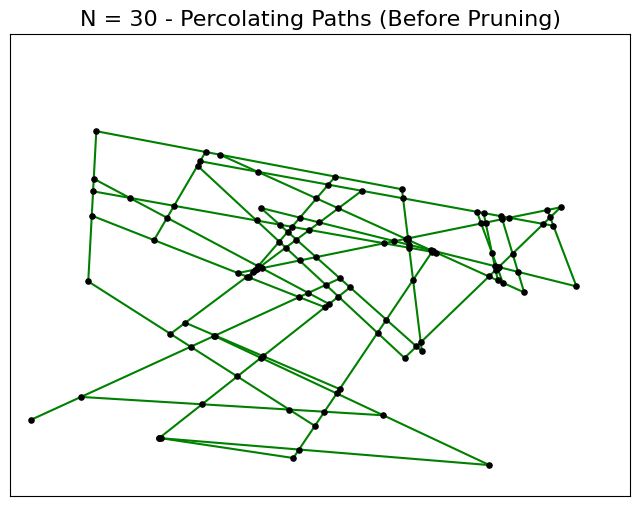

In [ ]:
# ═══════════════════════════════════════════════════════════════════════
# PLOT PERCOLATING PATHS (BEFORE PRUNING)
# ═══════════════════════════════════════════════════════════════════════
print("Visualization: Percolating paths (BEFORE pruning)")

fig_perc = plot_percolating_paths_before_pruning(
    intersections_points, graph, all_path_perc, path_nodes,
    points_1, points_2, N
)
if fig_perc:
    save_figure(fig_perc, f'03_percolating_paths_before_pruning_N{N}.png')
    plt.show()
else:
    print("No percolating paths to plot")

---
## 6. Check Percolation and Dead-Ends

In [ ]:
# ═══════════════════════════════════════════════════════════════════════
# STEP 1: CHECK PERCOLATION
# ═══════════════════════════════════════════════════════════════════════
print("="*70)
print("STEP 1: CHECK PERCOLATION")
print("="*70)

has_percolation = any(p == 1 for p in all_path_perc)

if has_percolation:
    n_perc = sum(1 for p in all_path_perc if p == 1)
    perc_indices = [i for i, p in enumerate(all_path_perc) if p == 1]
    perc_path_nodes = [path_nodes[i] for i in perc_indices]
    perc_path_pairs_of_lines = [path_pairs_of_lines[i] for i in perc_indices]
    perc_path_pairs_of_edges = [path_pairs_of_edges[i] for i in perc_indices]

    print(f"\nPercolating path(s) found: {n_perc}")
    for idx, i in enumerate(perc_indices):
        print(f"  Path {i}: {len(perc_path_nodes[idx])} nodes -> {perc_path_nodes[idx]}")

    # ═══════════════════════════════════════════════════════════════════
    # STEP 2: DISCOVER ALL EDGES (consecutive-only)
    # ═══════════════════════════════════════════════════════════════════
    print("\n" + "="*70)
    print("STEP 2: DISCOVER ALL EDGES IN PERCOLATING COMPONENT")
    print("="*70)

    all_perc_nodes_set = set()
    for nodes_list in perc_path_nodes:
        all_perc_nodes_set.update(nodes_list)

    segment_edge_list = discover_consecutive_edges(
        graph, intersections_points, all_perc_nodes_set, points_1, points_2
    )

    # Compare with BFS tree edges
    bfs_tree_edges = set()
    for edges_list in perc_path_pairs_of_edges:
        for n1, n2 in edges_list:
            bfs_tree_edges.add((min(n1, n2), max(n1, n2)))
    all_discovered_edges = set((min(n1, n2), max(n1, n2)) for seg, (n1, n2) in segment_edge_list)
    extra_edges = all_discovered_edges - bfs_tree_edges

    print(f"\n  Perc nodes: {len(all_perc_nodes_set)}")
    print(f"  BFS tree edges: {len(bfs_tree_edges)}")
    print(f"  ALL edges (consecutive): {len(all_discovered_edges)}")
    print(f"  Extra (parallel paths): {len(extra_edges)}")
    print(f"  Total segment-edge pairs: {len(segment_edge_list)}")

    # ═══════════════════════════════════════════════════════════════════
    # STEP 3: CHECK FOR DEAD-ENDS
    # ═══════════════════════════════════════════════════════════════════
    print("\n" + "="*70)
    print("STEP 3: CHECK FOR DEAD-ENDS")
    print("="*70)

    dangling_intern, has_dead_ends = check_dead_ends(
        segment_edge_list, source_segments, drain_segments
    )

    if has_dead_ends:
        print(f"\n  DEAD-ENDS FOUND: {len(dangling_intern)} internal dangling segment(s): {dangling_intern}")
    else:
        print(f"\n  No internal dead-ends. Network is clean.")
else:
    has_dead_ends = False
    perc_path_nodes = []
    perc_path_pairs_of_lines = []
    perc_path_pairs_of_edges = []
    segment_edge_list = []
    print(f"\n  NO percolating path found! Try increasing N or a.")

STEP 1: CHECK PERCOLATION

Percolating path(s) found: 1
  Path 0: 118 nodes -> [89, 27, 54, 60, 64, 90, 91, 92, 93, 26, 28, 29, 30, 18, 32, 45, 53, 55, 56, 57, 58, 19, 33, 46, 59, 61, 62, 63, 65, 66, 67, 39, 50, 78, 96, 102, 107, 22, 42, 51, 74, 84, 97, 104, 111, 112, 79, 98, 105, 114, 100, 106, 115, 13, 103, 14, 110, 10, 15, 23, 75, 113, 0, 16, 17, 20, 21, 24, 25, 1, 31, 34, 35, 36, 37, 38, 40, 41, 43, 44, 2, 47, 48, 49, 52, 4, 68, 80, 81, 82, 83, 85, 86, 7, 70, 99, 87, 116, 77, 3, 69, 71, 72, 73, 76, 11, 88, 117, 5, 6, 8, 9, 12, 94, 95, 101, 108, 109]

STEP 2: DISCOVER ALL EDGES IN PERCOLATING COMPONENT

  Perc nodes: 118
  BFS tree edges: 117
  ALL edges (consecutive): 206
  Extra (parallel paths): 183
  Total segment-edge pairs: 206

STEP 3: CHECK FOR DEAD-ENDS

  No internal dead-ends. Network is clean.


---
## 7. Apply Pruning (Remove Dead-Ends) and Verify Percolation

In [ ]:
# ═══════════════════════════════════════════════════════════════════════
# STEP 4-5: PRUNING + BUILD PRUNED DATA STRUCTURES
# ═══════════════════════════════════════════════════════════════════════
proceed_to_impedance = False

if not has_percolation:
    print("No percolating path. Skipping pruning.")
    filtered_segment_edge_list = []
else:
    print("="*70)
    print("STEP 4: NODE-BASED PRUNING")
    print("="*70)

    filtered_segment_edge_list, source_node_set, drain_node_set = prune_dead_end_nodes(
        segment_edge_list, intersections_points, verbose=True
    )

    print(f"\n  Source nodes (x < 0.1): {sorted(source_node_set)}")
    print(f"  Drain nodes (x > 0.9): {sorted(drain_node_set)}")

    if len(filtered_segment_edge_list) == 0:
        print("\n  All edges removed! No valid path.")
    else:
        proceed_to_impedance = True

    # STEP 5: Build pruned data structures
    print("\n" + "="*70)
    print("STEP 5: BUILD PRUNED DATA STRUCTURES")
    print("="*70)

    pruned_segments, filtered_nodes, filtered_pair_of_edges_flat, pruning_stats = \
        build_pruned_structures(segment_edge_list, filtered_segment_edge_list)

    # Unpack stats for downstream use
    nodes_before = pruning_stats['nodes_before']
    nodes_after = pruning_stats['nodes_after']
    removed_nodes = pruning_stats['removed_nodes']
    edges_before_set = pruning_stats['edges_before']
    edges_after_set = pruning_stats['edges_after']
    removed_edges = pruning_stats['removed_edges']
    segments_before = pruning_stats['segments_before']
    segments_removed = pruning_stats['segments_removed']
    segments_after = pruning_stats['segments_after']

    print(f"  Edges: {len(edges_before_set)} -> {len(edges_after_set)} (removed {len(removed_edges)})")
    print(f"  Nodes: {len(nodes_before)} -> {len(nodes_after)} (removed {len(removed_nodes)})")
    print(f"  Segments: {len(segments_before)} -> {len(segments_after)} (removed {len(segments_removed)})")

STEP 4: NODE-BASED PRUNING
  Pruning complete after 1 iteration(s).

  Source nodes (x < 0.1): [89]
  Drain nodes (x > 0.9): [71]

STEP 5: BUILD PRUNED DATA STRUCTURES
  Edges: 206 -> 206 (removed 0)
  Nodes: 118 -> 118 (removed 0)
  Segments: 29 -> 29 (removed 0)


In [ ]:
# ═══════════════════════════════════════════════════════════════════════
# STEP 6: VERIFY PRUNED PATH STILL PERCOLATES
# ═══════════════════════════════════════════════════════════════════════
if has_percolation:
    print("="*70)
    print("STEP 6: VERIFY PRUNED PATH STILL PERCOLATES")
    print("="*70)

    proceed_to_impedance = verify_pruned_percolation(
        filtered_segment_edge_list, intersections_points,
        source_segments, drain_segments
    )

    if proceed_to_impedance:
        print("\n  Pruned path STILL percolates!")
    else:
        print("\n  Pruned path NO LONGER percolates!")

print(f"\n>>> Proceed to impedance calculation: {proceed_to_impedance}")

STEP 6: VERIFY PRUNED PATH STILL PERCOLATES

  Pruned path STILL percolates!

>>> Proceed to impedance calculation: True


---
## 8. Visualize Network AFTER Pruning

In [ ]:
# ═══════════════════════════════════════════════════════════════════════
# PRUNING SUMMARY (from build_pruned_structures stats)
# ═══════════════════════════════════════════════════════════════════════
if has_percolation:
    print("="*70)
    print("PRUNING SUMMARY")
    print("="*70)
    print(f"\n  Segments BEFORE: {len(segments_before)} -> {sorted(segments_before)}")
    print(f"  Segments AFTER:  {len(segments_after)} -> {sorted(segments_after)}")
    print(f"  Segments REMOVED: {len(segments_removed)} -> {sorted(segments_removed)}")
    if removed_nodes:
        print(f"\n  Removed nodes: {sorted(removed_nodes)}")
        print(f"  Removed edges: {removed_edges}")

PRUNING SUMMARY

  Segments BEFORE: 29 -> [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29]
  Segments AFTER:  29 -> [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29]
  Segments REMOVED: 0 -> []


  [OK] Figure saved: 04_before_after_pruning_N30.png


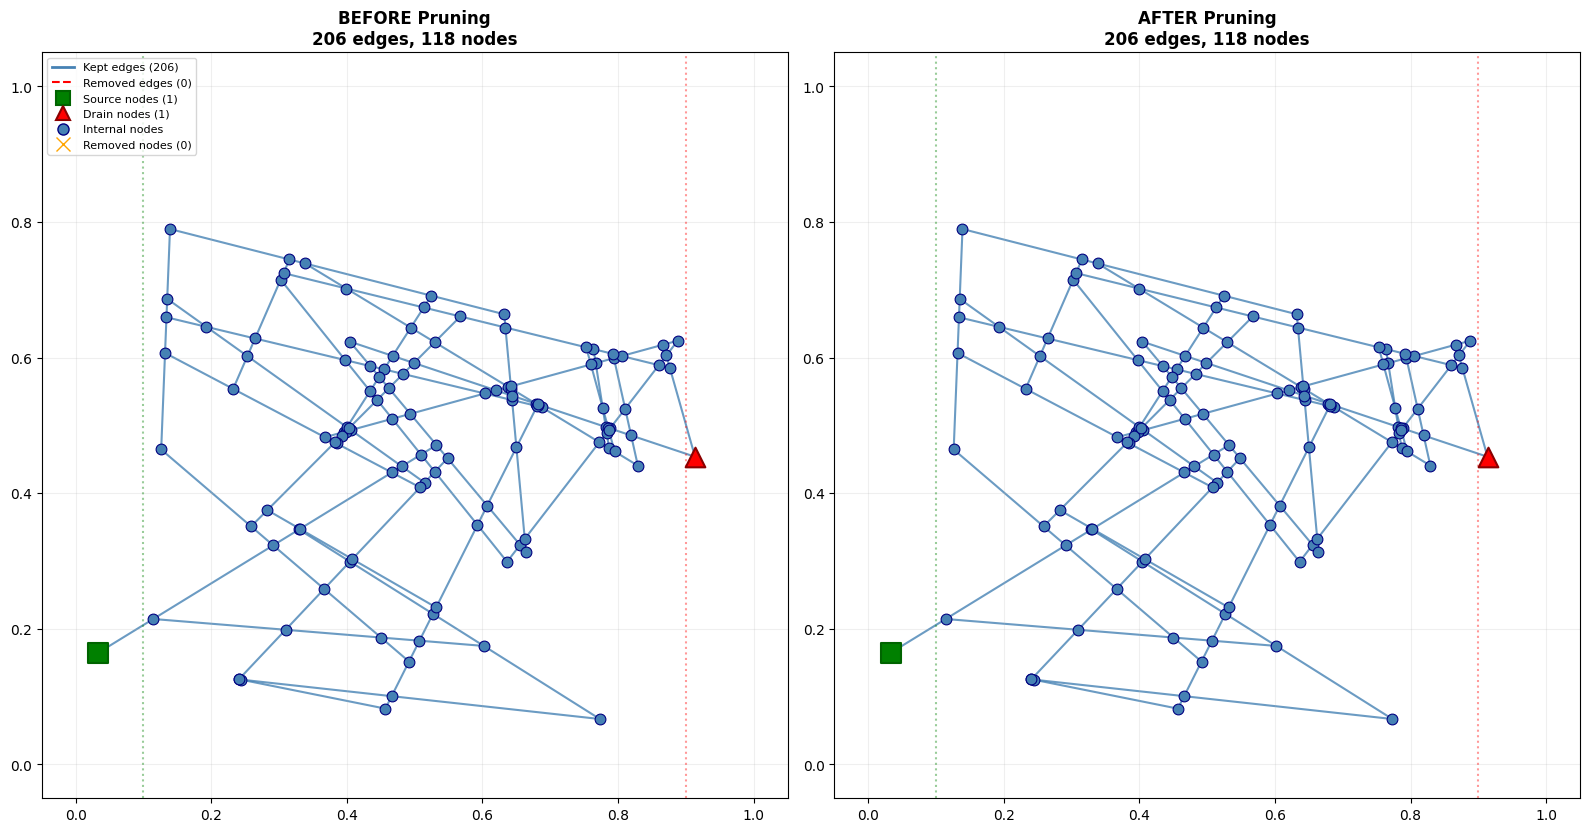

In [ ]:
# ═══════════════════════════════════════════════════════════════════════
# VISUALIZATION: BEFORE AND AFTER PRUNING
# ═══════════════════════════════════════════════════════════════════════
if not has_percolation or len(filtered_segment_edge_list) == 0:
    print("Nothing to visualize.")
else:
    fig_pruning, stats = plot_before_after_pruning(
        segment_edge_list, filtered_segment_edge_list,
        intersections_points, N
    )
    if fig_pruning:
        save_figure(fig_pruning, f'04_before_after_pruning_N{N}.png')
        plt.show()

---
## 9. Build Segment-to-Nodes Mapping for Impedance Calculation

In [ ]:
# ═══════════════════════════════════════════════════════════════════════
# BUILD CONNECTED PATH (filter to source-drain component)
# ═══════════════════════════════════════════════════════════════════════
if not proceed_to_impedance:
    print("Skipping: No valid percolating path after pruning.")
else:
    print("="*70)
    print("FILTERING TO CONNECTED PATH")
    print("="*70)

    segment_to_nodes, filtered_nodes = build_connected_path(
        filtered_segment_edge_list, filtered_nodes, intersections_points
    )

    print(f"\n  Connected nodes: {len(filtered_nodes)} -> {filtered_nodes}")
    print(f"  Unique edges (resistors): {len(segment_to_nodes)}")
    print(f"  segment_to_nodes: {segment_to_nodes}")

FILTERING TO CONNECTED PATH

  Connected nodes: 118 -> [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117]
  Unique edges (resistors): 206
  segment_to_nodes: {0: (0, 4), 1: (0, 10), 2: (0, 23), 3: (1, 7), 4: (1, 11), 5: (1, 34), 6: (1, 43), 7: (2, 7), 8: (2, 12), 9: (2, 47), 10: (2, 52), 11: (3, 10), 12: (3, 11), 13: (3, 75), 14: (3, 76), 15: (4, 6), 16: (4, 80), 17: (4, 85), 18: (5, 12), 19: (5, 48), 20: (5, 87), 21: (6, 8), 22: (6, 80), 23: (7, 70), 24: (7, 99), 25: (8, 9), 26: (8, 82), 27: (9, 73), 28: (10, 23), 29: (10, 75), 30: (11, 43), 31: (11, 76), 32: (12

In [ ]:
# ═══════════════════════════════════════════════════════════════════════
# REBUILD LOCAL GRAPH WITH CONSECUTIVE INDICES
# ═══════════════════════════════════════════════════════════════════════
if not proceed_to_impedance:
    print("Skipping: No valid percolating path after pruning.")
else:
    print("="*70)
    print("REBUILDING LOCAL GRAPH")
    print("="*70)

    node_mapping, path_intersections, new_segment_to_nodes, path_graph = \
        rebuild_local_graph(filtered_nodes, intersections_points, segment_to_nodes)

    nodes_in_path = sorted(filtered_nodes)

    print(f"\n  Nodes: {len(path_intersections)}")
    print(f"  Segments: {len(new_segment_to_nodes)}")
    print(f"  Node mapping: {node_mapping}")
    print(f"  segment_to_nodes: {new_segment_to_nodes}")

REBUILDING LOCAL GRAPH

  Nodes: 118
  Segments: 206
  Node mapping: {0: 0, 1: 1, 2: 2, 3: 3, 4: 4, 5: 5, 6: 6, 7: 7, 8: 8, 9: 9, 10: 10, 11: 11, 12: 12, 13: 13, 14: 14, 15: 15, 16: 16, 17: 17, 18: 18, 19: 19, 20: 20, 21: 21, 22: 22, 23: 23, 24: 24, 25: 25, 26: 26, 27: 27, 28: 28, 29: 29, 30: 30, 31: 31, 32: 32, 33: 33, 34: 34, 35: 35, 36: 36, 37: 37, 38: 38, 39: 39, 40: 40, 41: 41, 42: 42, 43: 43, 44: 44, 45: 45, 46: 46, 47: 47, 48: 48, 49: 49, 50: 50, 51: 51, 52: 52, 53: 53, 54: 54, 55: 55, 56: 56, 57: 57, 58: 58, 59: 59, 60: 60, 61: 61, 62: 62, 63: 63, 64: 64, 65: 65, 66: 66, 67: 67, 68: 68, 69: 69, 70: 70, 71: 71, 72: 72, 73: 73, 74: 74, 75: 75, 76: 76, 77: 77, 78: 78, 79: 79, 80: 80, 81: 81, 82: 82, 83: 83, 84: 84, 85: 85, 86: 86, 87: 87, 88: 88, 89: 89, 90: 90, 91: 91, 92: 92, 93: 93, 94: 94, 95: 95, 96: 96, 97: 97, 98: 98, 99: 99, 100: 100, 101: 101, 102: 102, 103: 103, 104: 104, 105: 105, 106: 106, 107: 107, 108: 108, 109: 109, 110: 110, 111: 111, 112: 112, 113: 113, 114: 114, 

---
## 10. Calculate Impedance

In [ ]:
# ═══════════════════════════════════════════════════════════════════════
# MERGE BOUNDARY NODES AND CALCULATE IMPEDANCE
# ═══════════════════════════════════════════════════════════════════════
print("="*70)
print("MERGING BOUNDARY NODES INTO SINGLE SOURCE/DRAIN")
print("="*70)

if not proceed_to_impedance:
    print("\nCannot calculate impedance: No valid percolating path.")
    result = None
    merged_intersections = None
else:
    k = 1000  # Ohms per segment
    print(f"\n  k = {k} ohm per segment")

    # Find source/drain in local indices
    source_nodes_pruned = [n for n in filtered_nodes if intersections_points[n][0] < 0.1]
    drain_nodes_pruned = [n for n in filtered_nodes if intersections_points[n][0] > 0.9]
    source_boundary_new = [node_mapping[n] for n in source_nodes_pruned if n in node_mapping]
    drain_boundary_new = [node_mapping[n] for n in drain_nodes_pruned if n in node_mapping]

    print(f"  Source boundary (local): {source_boundary_new}")
    print(f"  Drain boundary (local): {drain_boundary_new}")

    # Merge
    (merged_intersections, merged_graph, merged_segment_to_nodes,
     merged_source_node, merged_drain_node, merge_mapping, edge_conductance) = merge_boundary_nodes(
        path_intersections, path_graph, new_segment_to_nodes,
        source_boundary_new, drain_boundary_new
    )

    print(f"\n  Nodes: {len(path_intersections)} -> {len(merged_intersections)}")
    print(f"  Edges: {len(new_segment_to_nodes)} -> {len(merged_segment_to_nodes)}")

    # Merge report
    nodes_merged_to_source, nodes_merged_to_drain = print_merge_report(
        path_intersections, merged_intersections,
        merge_mapping, merged_source_node, merged_drain_node,
        merged_segment_to_nodes, edge_conductance,
        nodes_in_path, intersections_points,
        source_boundary_new, drain_boundary_new
    )

    # Calculate impedance
    print("\n" + "="*70)
    print("CALCULATING IMPEDANCE")
    print("="*70)

    calc = ImpedanceCalculator(merged_intersections, merged_graph, merged_segment_to_nodes,
                               edge_conductance=edge_conductance)
    result = calc.calculate(k=k, verbose=True)
    print()
    calc.print_summary(result)

MERGING BOUNDARY NODES INTO SINGLE SOURCE/DRAIN

  k = 1000 ohm per segment
  Source boundary (local): [89]
  Drain boundary (local): [71]

  Nodes: 118 -> 118
  Edges: 206 -> 206
MERGE REPORT

  BEFORE: 118 nodes
    1 SOURCE (x < 0.1), 1 DRAIN (x > 0.9), 116 INTERNAL

  AFTER:  118 nodes
    1 merged SOURCE (index 116), 1 merged DRAIN (index 117), 116 INTERNAL

  Edges: 206

CALCULATING IMPEDANCE

Source node: 116
Drain node: 117
Number of nodes: 118
Number of edges: 206

Connectivity check:
  Reachable nodes: 118/118
  Drain reachable: True

Incidence matrix A (206x118):
[[-1.  0.  0. ...  0.  0.  0.]
 [-1.  0.  0. ...  0.  0.  0.]
 [-1.  0.  0. ...  0.  0.  0.]
 ...
 [ 0.  0.  0. ...  1.  0.  0.]
 [ 0.  0.  0. ...  0.  0.  0.]
 [ 0.  0.  0. ...  0.  0.  0.]]

Conductance matrix G (diagonal):
  Base conductance = 1/1000 = 0.001000
  Edge conductance multipliers: {0: 1, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 6: 1, 7: 1, 8: 1, 9: 1, 10: 1, 11: 1, 12: 1, 13: 1, 14: 1, 15: 1, 16: 1, 17: 1, 18: 1

In [ ]:
# ═══════════════════════════════════════════════════════════════════════
# TEST WITH DIFFERENT RESISTANCE VALUES (on merged network)
# ═══════════════════════════════════════════════════════════════════════
if proceed_to_impedance and result and merged_intersections:
    print("\n" + "─"*70)
    print("IMPEDANCE FOR DIFFERENT RESISTANCE VALUES (Merged Network)")
    print("─"*70)

    for k_value in [1, 10, 100, 1000, 10000]:
        calc_test = ImpedanceCalculator(merged_intersections, merged_graph, merged_segment_to_nodes,
                                       edge_conductance=edge_conductance)
        result_test = calc_test.calculate(k=k_value, verbose=False)
        print(f"  k = {k_value:5d} Ω  →  R_equivalent = {result_test['impedance']:.4f} Ω")
else:
    print("Skipping: No impedance result available.")


──────────────────────────────────────────────────────────────────────
IMPEDANCE FOR DIFFERENT RESISTANCE VALUES (Merged Network)
──────────────────────────────────────────────────────────────────────
  k =     1 Ω  →  R_equivalent = 4.5143 Ω
  k =    10 Ω  →  R_equivalent = 45.1426 Ω
  k =   100 Ω  →  R_equivalent = 451.4255 Ω
  k =  1000 Ω  →  R_equivalent = 4514.2554 Ω
  k = 10000 Ω  →  R_equivalent = 45142.5542 Ω


---
## 11. Final Network Visualization with Impedance Info

  [OK] Figure saved: network_merge_explained.png


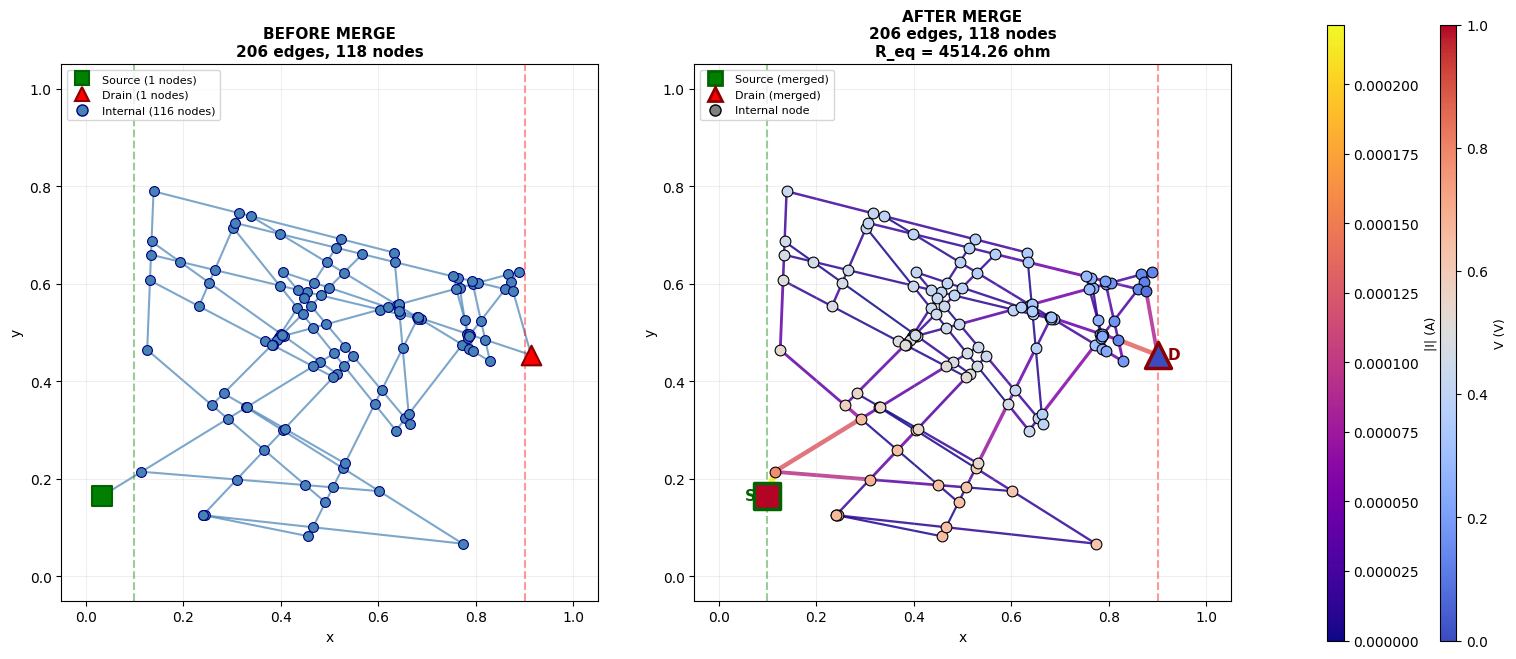

DETAILED IMPEDANCE CALCULATION

  MERGED NETWORK: 118 nodes, 206 edges, k = 1000 ohm

--------------------------------------------------------------------------------
INCIDENCE MATRIX A (edges x nodes)
--------------------------------------------------------------------------------
          I0   I1   I2   I3   I4   I5   I6   I7   I8   I9   I10   I11   I12   I13   I14   I15   I16   I17   I18   I19   I20   I21   I22   I23   I24   I25   I26   I27   I28   I29   I30   I31   I32   I33   I34   I35   I36   I37   I38   I39   I40   I41   I42   I43   I44   I45   I46   I47   I48   I49   I50   I51   I52   I53   I54   I55   I56   I57   I58   I59   I60   I61   I62   I63   I64   I65   I66   I67   I68   I69   I70   I71   I72   I73   I74   I75   I76   I77   I78   I79   I80   I81   I82   I83   I84   I85   I86   I87   I88   I89   I90   I91   I92   I93   I94   I95   I96   I97   I98   I99   I100   I101   I102   I103   I104   I105   I106   I107   I108   I109   I110   I111   I112   I113   I114   I115    S   

In [ ]:
# ═══════════════════════════════════════════════════════════════════════
# MERGE VISUALIZATION + DETAILED IMPEDANCE CALCULATION
# ═══════════════════════════════════════════════════════════════════════
if proceed_to_impedance and result and merged_intersections:
    # PART 1: Before/After merge visualization
    fig_merge = plot_before_after_merge(
        filtered_segment_edge_list, filtered_nodes,
        intersections_points, merged_intersections,
        merged_segment_to_nodes, merged_source_node,
        merged_drain_node, edge_conductance, result, k
    )
    if fig_merge:
        save_figure(fig_merge, 'network_merge_explained.png')
        plt.show()

    # PART 2: Detailed impedance calculation (matrices, solution)
    R_calc, total_source_current = print_detailed_impedance(
        merged_segment_to_nodes, merged_intersections,
        merged_source_node, merged_drain_node,
        edge_conductance, result, k
    )
else:
    print("  No impedance result available for visualization.")

In [ ]:
# ============================================================================
# EXPORT EXPERIMENT SUMMARY
# ============================================================================
voltages = result['voltages'] if result else None
currents = result['currents'] if result else None

# Calculate impedance for different k values
impedance_vs_k = {}
if proceed_to_impedance and result and merged_intersections:
    impedance_vs_k = calculate_impedance_vs_k(
        ImpedanceCalculator, merged_intersections, merged_graph,
        merged_segment_to_nodes, edge_conductance
    )

# Build detailed structures using result_exporter functions
nodes_detailed = build_nodes_detailed(filtered_nodes, intersections_points, voltages)
edges_detailed = build_edges_detailed(filtered_segment_edge_list, edge_conductance if 'edge_conductance' in dir() else {}, voltages, currents)
percolating_paths_detailed = build_percolating_paths_detailed(all_path_perc, path_nodes, path_pairs_of_edges)
lines_info = build_lines_info(points_1, points_2, angles)

# Build comprehensive experiment summary
experiment_summary = build_experiment_summary(
    N=N, a=a, timestamp=EXPERIMENT_TIMESTAMP, in_colab=IN_COLAB,
    intersections_points=intersections_points, lines_info=lines_info,
    has_percolation=has_percolation, n_perc=n_perc if 'n_perc' in dir() else 0,
    percolating_paths_detailed=percolating_paths_detailed,
    source_node_set=source_node_set if 'source_node_set' in dir() else set(),
    drain_node_set=drain_node_set if 'drain_node_set' in dir() else set(),
    nodes_before=nodes_before if 'nodes_before' in dir() else set(),
    nodes_after=nodes_after if 'nodes_after' in dir() else set(),
    removed_nodes=removed_nodes if 'removed_nodes' in dir() else set(),
    edges_before_set=edges_before_set if 'edges_before_set' in dir() else set(),
    edges_after_set=edges_after_set if 'edges_after_set' in dir() else set(),
    removed_edges=removed_edges if 'removed_edges' in dir() else set(),
    segments_before=segments_before if 'segments_before' in dir() else set(),
    segments_after=segments_after if 'segments_after' in dir() else set(),
    segments_removed=segments_removed if 'segments_removed' in dir() else set(),
    dead_end_nodes=dead_end_nodes if 'dead_end_nodes' in dir() else [],
    nodes_detailed=nodes_detailed, edges_detailed=edges_detailed,
    merged_source_node=merged_source_node if 'merged_source_node' in dir() else None,
    merged_drain_node=merged_drain_node if 'merged_drain_node' in dir() else None,
    nodes_merged_to_source=nodes_merged_to_source if 'nodes_merged_to_source' in dir() else [],
    nodes_merged_to_drain=nodes_merged_to_drain if 'nodes_merged_to_drain' in dir() else [],
    merge_mapping=merge_mapping if 'merge_mapping' in dir() else {},
    merged_graph=merged_graph if 'merged_graph' in dir() else None,
    merged_intersections=merged_intersections if 'merged_intersections' in dir() else None,
    R_calc=R_calc if 'R_calc' in dir() else None,
    I=None,
    total_source_current=total_source_current if 'total_source_current' in dir() else None,
    impedance_vs_k=impedance_vs_k,
    voltages=voltages, currents=currents,
    edge_conductance=edge_conductance if 'edge_conductance' in dir() else {},
    merged_segment_to_nodes=merged_segment_to_nodes if 'merged_segment_to_nodes' in dir() else {},
)

# Save files
save_json(experiment_summary, "experiment_summary.json")
save_json(intersections_points, "all_intersections.json")
save_json(lines_info, "lines_generated.json")
save_json(nodes_detailed, "nodes_detailed.json")
save_json(edges_detailed, "edges_detailed.json")
save_json(percolating_paths_detailed, "percolating_paths.json")

# Save network data for future reloading
exp_manager.save_network(N, a, points_1, points_2, angles)

if 'merged_segment_to_nodes' in dir() and merged_segment_to_nodes:
    merged_graph_detailed = [{"node1": int(n1), "node2": int(n2)} for seg_idx, (n1, n2) in merged_segment_to_nodes.items()]
    save_json(merged_graph_detailed, "merged_graph.json")
if 'segment_edge_list' in dir():
    save_json(segment_edge_list, "segment_edge_list_original.json")
if 'filtered_segment_edge_list' in dir():
    save_json(filtered_segment_edge_list, "segment_edge_list_pruned.json")

# Print summaries
if impedance_vs_k:
    print_impedance_summary(impedance_vs_k)

files_saved = [
    "experiment_summary.json", "all_intersections.json", "lines_generated.json",
    "nodes_detailed.json", "edges_detailed.json", "percolating_paths.json",
    "network_data.json",
    "merged_graph.json", "segment_edge_list_original.json", "segment_edge_list_pruned.json",
]
print_export_summary(EXPERIMENT_DIR, files_saved)

  [OK] JSON saved: experiment_summary.json

Generating PDFs...
  [OK] Individual PDF saved: <project_root>/utils/../experiments/exp_72/experiment_72_report.pdf
  [OK] General PDF saved: <project_root>/utils/../experiments/all_experiments_report.pdf  (34 complete + 38 partial experiments)
PDF generation complete.

  [OK] JSON saved: all_intersections.json
  [OK] JSON saved: lines_generated.json
  [OK] JSON saved: nodes_detailed.json
  [OK] JSON saved: edges_detailed.json
  [OK] JSON saved: percolating_paths.json
  [OK] JSON saved: merged_graph.json
  [OK] JSON saved: segment_edge_list_original.json
  [OK] JSON saved: segment_edge_list_pruned.json

------------------------------------------------------------
IMPEDANCE RESULTS FOR DIFFERENT k VALUES:
------------------------------------------------------------
  k =     1 Ohm  ->  R_equivalent = 4.5143 Ohm
  k =    10 Ohm  ->  R_equivalent = 45.1426 Ohm
  k =   100 Ohm  ->  R_equivalent = 451.4255 Ohm
  k =  1000 Ohm  ->  R_equivalent = 4